# project

works on **kaggle** and on your **own laptop** (jupyter). read every cell, run it, then break it and fix it. that is how you learn.

**what you will do**
1. regression from scratch + plotting (loss, overfitting)
2. regression on a real csv dataset (dataset 1)
3. image basics: pixels, convolution, pooling by hand (dataset 2)
4. your first CNN in pytorch on MNIST digits
5. handwritten letters with EMNIST (dataset 3), closest to our project

**the 3 datasets**

| # | name | how you get it | what you learn |
|---|------|----------------|----------------|
| 1 | Medical Cost Personal Datasets (`mirichoi0218/insurance`) | kaggle: Add Input -> search "insurance" -> add. laptop: download csv, put next to notebook | upload/link a csv, regression |
| 2 | MNIST digits | auto download using torchvision (no upload needed) | images as numbers, first CNN |
| 3 | EMNIST letters (`crawford/emnist`) | kaggle: Add Input -> search "emnist" -> add. laptop: download from kaggle, put the csv next to notebook | link an image dataset, handwritten letters |

**kaggle setup checklist**
- verify phone number (needed for gpu + internet)
- notebook settings -> Accelerator -> GPU T4 (or P100)
- notebook settings -> Internet -> On (needed for MNIST download)
- right side -> Add Input -> search the dataset -> Add

In [1]:
import os, glob, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

ON_KAGGLE = os.path.exists("/kaggle/input")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("running on kaggle:", ON_KAGGLE)
print("device:", device)   # kaggle gpu on = cuda, laptop usually cpu (that is fine)

# same seed = same results every time
random.seed(42); np.random.seed(42); torch.manual_seed(42)

def find_file(name_part):
    # looks for a file inside /kaggle/input (kaggle) or current folder (laptop)
    root = "/kaggle/input" if ON_KAGGLE else "."
    hits = glob.glob(f"{root}/**/*{name_part}*", recursive=True)
    return hits[0] if hits else None

running on kaggle: True
device: cpu


## part 1: regression from scratch

idea: we have points (x, y). we want the best line `y = w*x + b`.
- **prediction** = w*x + b
- **loss** = mean of (prediction - real)^2   (how wrong we are)
- **gradient descent** = nudge w and b in the direction that reduces loss

this exact idea (loss + gradient + update) is what a neural network does too. only the model is bigger.

learned w=nan, b=nan  (true: 3 and 5)


/tmp/ipykernel_1685/4167500704.py:12: RuntimeWarning: overflow encountered in square
  loss = np.mean((pred - y) ** 2)
/tmp/ipykernel_1685/4167500704.py:11: RuntimeWarning: invalid value encountered in multiply
  pred = w * x + b


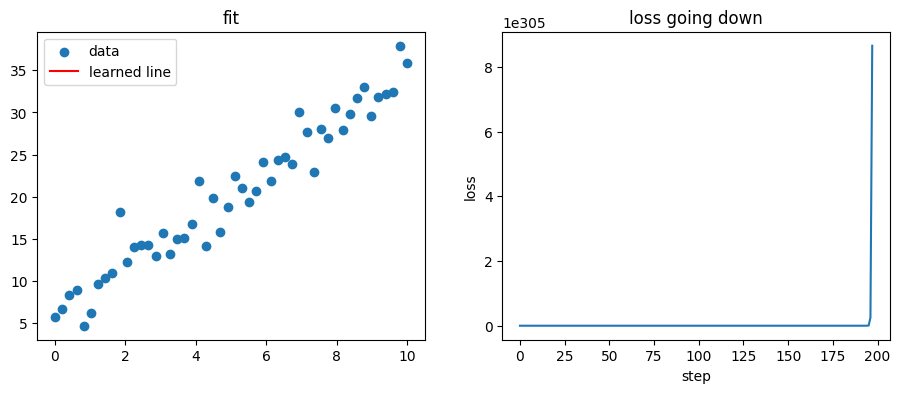

In [6]:
# fake data: true line is y = 3x + 5 plus noise
x = np.linspace(0, 10, 50)
y = 3 * x + 5 + np.random.randn(50) * 2

w, b = 0.0, 0.0
#When lr=0.1
lr = 0.1
losses = []

for step in range(500):
    pred = w * x + b
    loss = np.mean((pred - y) ** 2)
    losses.append(loss)
    # gradients (calculus: derivative of loss wrt w and b)
    dw = np.mean(2 * (pred - y) * x)
    db = np.mean(2 * (pred - y))
    w -= lr * dw
    b -= lr * db

print(f"learned w={w:.2f}, b={b:.2f}  (true: 3 and 5)")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(x, y, label="data")
ax[0].plot(x, w * x + b, color="red", label="learned line")
ax[0].set_title("fit"); ax[0].legend()
ax[1].plot(losses)
ax[1].set_title("loss going down"); ax[1].set_xlabel("step"); ax[1].set_ylabel("loss")
plt.show()

learned w=3.49, b=1.69  (true: 3 and 5)


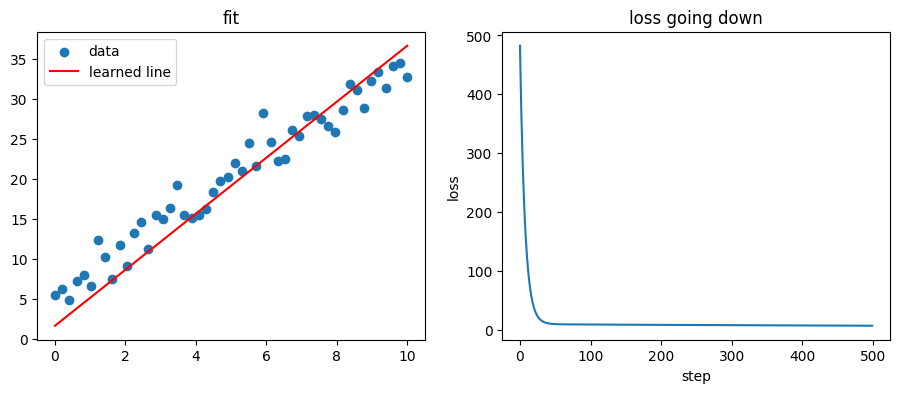

In [5]:
# fake data: true line is y = 3x + 5 plus noise
x = np.linspace(0, 10, 50)
y = 3 * x + 5 + np.random.randn(50) * 2

w, b = 0.0, 0.0
#When lr=0.001
lr = 0.001
losses = []

for step in range(500):
    pred = w * x + b
    loss = np.mean((pred - y) ** 2)
    losses.append(loss)
    # gradients (calculus: derivative of loss wrt w and b)
    dw = np.mean(2 * (pred - y) * x)
    db = np.mean(2 * (pred - y))
    w -= lr * dw
    b -= lr * db

print(f"learned w={w:.2f}, b={b:.2f}  (true: 3 and 5)")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(x, y, label="data")
ax[0].plot(x, w * x + b, color="red", label="learned line")
ax[0].set_title("fit"); ax[0].legend()
ax[1].plot(losses)
ax[1].set_title("loss going down"); ax[1].set_xlabel("step"); ax[1].set_ylabel("loss")
plt.show()

learned w=3.55, b=0.63  (true: 3 and 5)


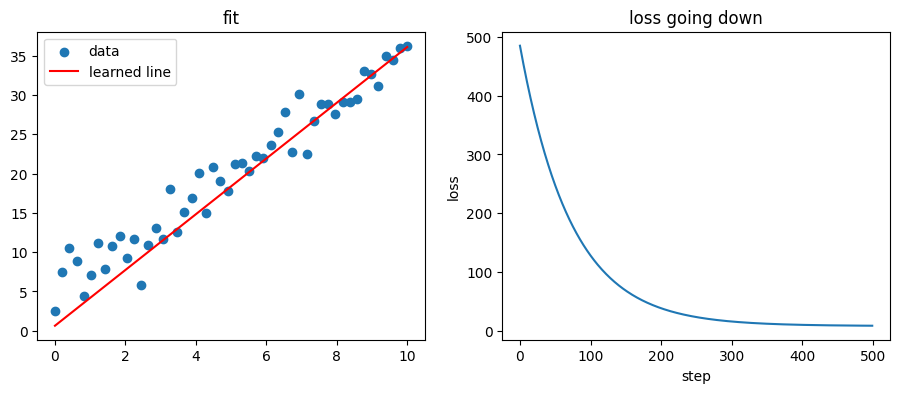

In [7]:
# fake data: true line is y = 3x + 5 plus noise
x = np.linspace(0, 10, 50)
y = 3 * x + 5 + np.random.randn(50) * 2

w, b = 0.0, 0.0
#When lr=0.0001
lr = 0.0001
losses = []

for step in range(500):
    pred = w * x + b
    loss = np.mean((pred - y) ** 2)
    losses.append(loss)
    # gradients (calculus: derivative of loss wrt w and b)
    dw = np.mean(2 * (pred - y) * x)
    db = np.mean(2 * (pred - y))
    w -= lr * dw
    b -= lr * db

print(f"learned w={w:.2f}, b={b:.2f}  (true: 3 and 5)")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(x, y, label="data")
ax[0].plot(x, w * x + b, color="red", label="learned line")
ax[0].set_title("fit"); ax[0].legend()
ax[1].plot(losses)
ax[1].set_title("loss going down"); ax[1].set_xlabel("step"); ax[1].set_ylabel("loss")
plt.show()

### overfitting demo
we fit curves of different complexity on noisy sine data. train error keeps falling but test error eventually goes up. that is overfitting.

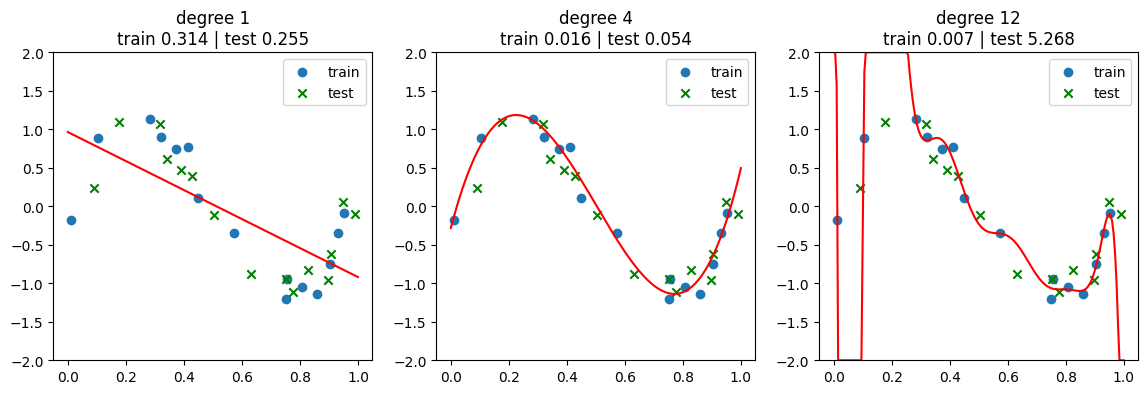

In [8]:
xs = np.sort(np.random.uniform(0, 1, 30))
ys = np.sin(2 * np.pi * xs) + np.random.randn(30) * 0.25
x_train, y_train = xs[::2], ys[::2]     # 15 points to learn from
x_test,  y_test  = xs[1::2], ys[1::2]   # 15 points hidden from the model

grid = np.linspace(0, 1, 200)
plt.figure(figsize=(14, 4))
for i, degree in enumerate([1, 4, 12]):
    coef = np.polyfit(x_train, y_train, degree)
    tr_err = np.mean((np.polyval(coef, x_train) - y_train) ** 2)
    te_err = np.mean((np.polyval(coef, x_test) - y_test) ** 2)
    plt.subplot(1, 3, i + 1)
    plt.scatter(x_train, y_train, label="train")
    plt.scatter(x_test, y_test, marker="x", color="green", label="test")
    plt.plot(grid, np.clip(np.polyval(coef, grid), -2, 2), color="red")
    plt.ylim(-2, 2)
    plt.title(f"degree {degree}\ntrain {tr_err:.3f} | test {te_err:.3f}")
    plt.legend()
plt.show()
# degree 1 = underfit, degree 4 = good, degree 12 = overfit (wiggly, great on train, bad on test)

## part 2: regression on a real dataset (dataset 1: insurance.csv)

**kaggle:** Add Input -> search `insurance` -> pick "Medical Cost Personal Datasets" -> Add.
**laptop:** download `insurance.csv` from kaggle and keep it in the same folder as this notebook.

goal: predict `charges` (medical bill) from age, bmi, smoker, etc.

In [13]:
df = pd.read_csv("/content/drive/MyDrive/insurance.csv")
display(df.head())
print(df.shape)
display(df.describe())
df.columns
df.info()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


(1338, 7)


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


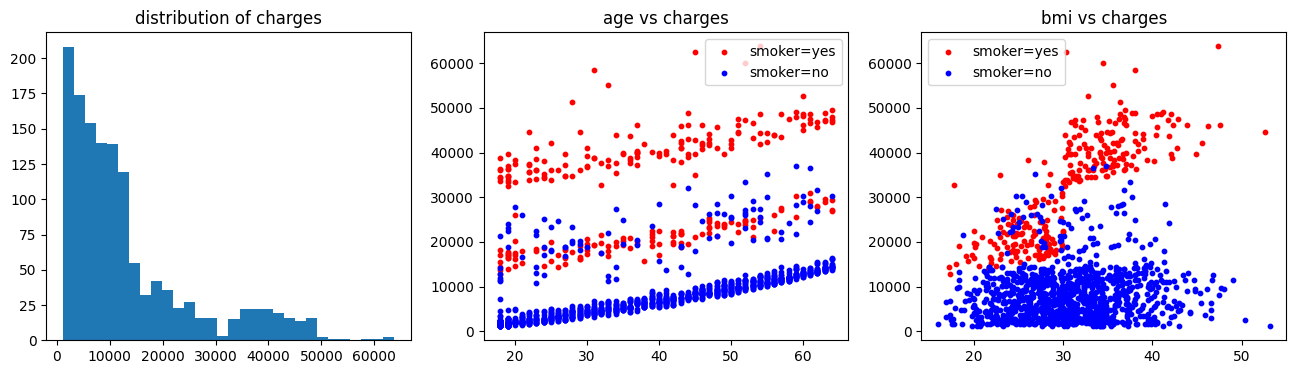

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(df["charges"], bins=30); ax[0].set_title("distribution of charges")
for s, c in [("yes", "red"), ("no", "blue")]:
    sub = df[df["smoker"] == s]
    ax[1].scatter(sub["age"], sub["charges"], s=10, c=c, label=f"smoker={s}")
ax[1].set_title("age vs charges"); ax[1].legend()
for s, c in [("yes", "red"), ("no", "blue")]:
    sub = df[df["smoker"] == s]
    ax[2].scatter(sub["bmi"], sub["charges"], s=10, c=c, label=f"smoker={s}")
ax[2].set_title("bmi vs charges"); ax[2].legend()
plt.show()
# notice: smoker changes everything. plotting first tells you what matters.

train R2: 0.742
test  R2: 0.784
avg error (MAE): 4181.2


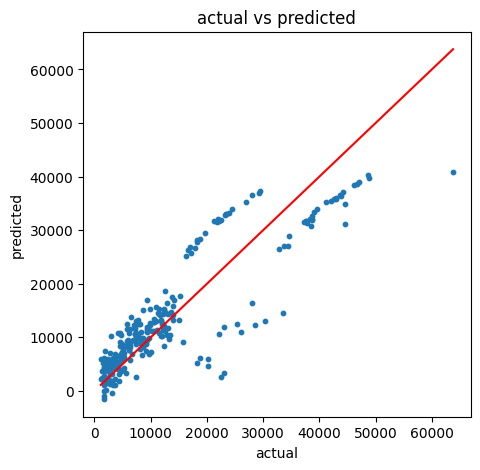

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# text columns -> numbers (one-hot encoding)
data = pd.get_dummies(df, drop_first=True)
X = data.drop("charges", axis=1)
y = data["charges"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)          # training
pred = model.predict(X_test)         # testing on unseen data

print("train R2:", round(model.score(X_train, y_train), 3))
print("test  R2:", round(r2_score(y_test, pred), 3))
print("avg error (MAE):", round(mean_absolute_error(y_test, pred), 1))

plt.figure(figsize=(5, 5))
plt.scatter(y_test, pred, s=10)
lims = [y.min(), y.max()]
plt.plot(lims, lims, color="red")    # perfect prediction line
plt.xlabel("actual"); plt.ylabel("predicted"); plt.title("actual vs predicted")
plt.show()

## part 3: images are just numbers (dataset 2: MNIST)

MNIST = 70,000 handwritten digits (0 to 9), each 28x28 pixels. downloads automatically.
on kaggle, internet must be ON in settings.

100%|██████████| 9.91M/9.91M [00:01<00:00, 6.54MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 155kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.46MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.9MB/s]


train images: torch.Size([60000, 28, 28]) | test images: torch.Size([10000, 28, 28])


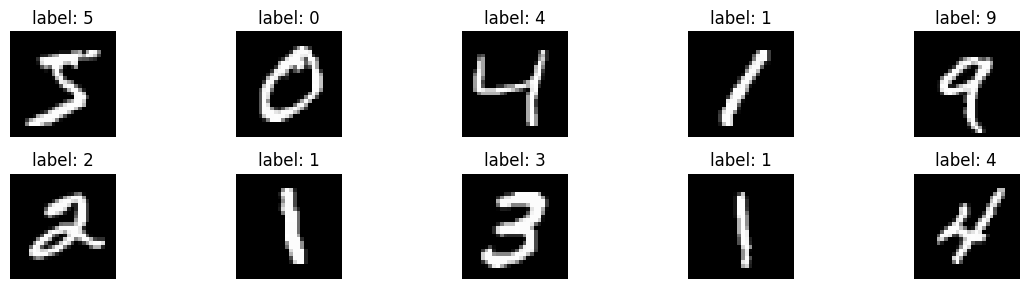

In [16]:
from torchvision import datasets

train_ds = datasets.MNIST(root="./data", train=True, download=True)
test_ds  = datasets.MNIST(root="./data", train=False, download=True)

X_tr_raw, y_tr = train_ds.data, train_ds.targets     # uint8 tensors, 0 to 255
X_te_raw, y_te = test_ds.data, test_ds.targets
print("train images:", X_tr_raw.shape, "| test images:", X_te_raw.shape)

plt.figure(figsize=(12, 3))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_tr_raw[i], cmap="gray")
    plt.title(f"label: {y_tr[i].item()}")
    plt.axis("off")
plt.tight_layout(); plt.show()

In [17]:
# one image = 28x28 grid of numbers. 0 = black, 255 = white.
img = X_tr_raw[0].numpy()
print(img.shape)
print(img[8:20, 8:20])    # a small piece of the numbers

(28, 28)
[[219 253 253 253 253 253 198 182 247 241   0   0]
 [ 80 156 107 253 253 205  11   0  43 154   0   0]
 [  0  14   1 154 253  90   0   0   0   0   0   0]
 [  0   0   0 139 253 190   2   0   0   0   0   0]
 [  0   0   0  11 190 253  70   0   0   0   0   0]
 [  0   0   0   0  35 241 225 160 108   1   0   0]
 [  0   0   0   0   0  81 240 253 253 119  25   0]
 [  0   0   0   0   0   0  45 186 253 253 150  27]
 [  0   0   0   0   0   0   0  16  93 252 253 187]
 [  0   0   0   0   0   0   0   0   0 249 253 249]
 [  0   0   0   0   0   0  46 130 183 253 253 207]
 [  0   0   0   0  39 148 229 253 253 253 250 182]]


### convolution by hand
a CNN slides a small grid (**kernel / filter**) over the image and multiplies + adds at each spot. different kernels detect different things (edges, lines, curves). the CNN **learns** the kernel values by itself during training.

feature map: (26, 26) -> after pooling: (13, 13)


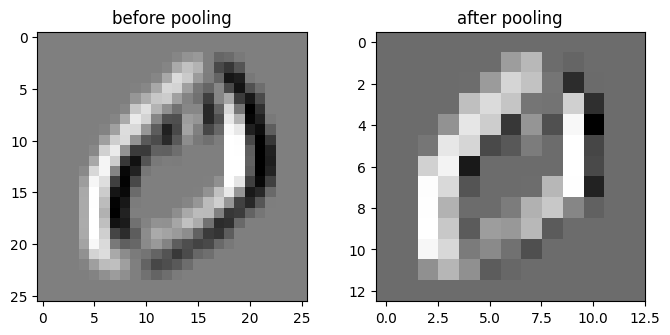

In [21]:
# max pooling: take the max of every 2x2 block -> image becomes half size, keeps strongest signals
def max_pool(fm, size=2):
    H, W = fm.shape
    H, W = H - H % size, W - W % size
    fm = fm[:H, :W]
    return fm.reshape(H // size, size, W // size, size).max(axis=(1, 3))

pooled = max_pool(fm_v)
print("feature map:", fm_v.shape, "-> after pooling:", pooled.shape)
plt.figure(figsize=(8, 3.5))
plt.subplot(1, 2, 1); plt.imshow(fm_v, cmap="gray"); plt.title("before pooling")
plt.subplot(1, 2, 2); plt.imshow(pooled, cmap="gray"); plt.title("after pooling")
plt.show()

## part 4: your first CNN in pytorch

flow: **data -> model -> loss -> backprop -> optimizer step**, repeated for many batches (an epoch = one full pass over the data).

In [22]:
# prepare data: scale to 0-1, normalize, add channel dimension (N, 1, 28, 28)
def prep(x):
    x = x.float().unsqueeze(1) / 255.0
    return (x - 0.1307) / 0.3081

train_loader = DataLoader(TensorDataset(prep(X_tr_raw), y_tr), batch_size=128, shuffle=True)
test_loader  = DataLoader(TensorDataset(prep(X_te_raw), y_te), batch_size=512)

class SimpleCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)    # 28x28 -> 28x28, 16 feature maps
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)   # 14x14 -> 14x14, 32 feature maps
        self.fc1 = nn.Linear(32 * 7 * 7, 64)
        self.fc2 = nn.Linear(64, num_classes)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)   # -> 16 x 14 x 14
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)   # -> 32 x 7 x 7
        x = x.flatten(1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

model = SimpleCNN().to(device)
print(model)
print("total parameters:", sum(p.numel() for p in model.parameters()))

SimpleCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=1568, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=10, bias=True)
)
total parameters: 105866


epoch 1/3 | train loss 0.0797 acc 0.9757 | test loss 0.0694 acc 0.9766
epoch 2/3 | train loss 0.0542 acc 0.9835 | test loss 0.0593 acc 0.9807
epoch 3/3 | train loss 0.0333 acc 0.9900 | test loss 0.0402 acc 0.9868


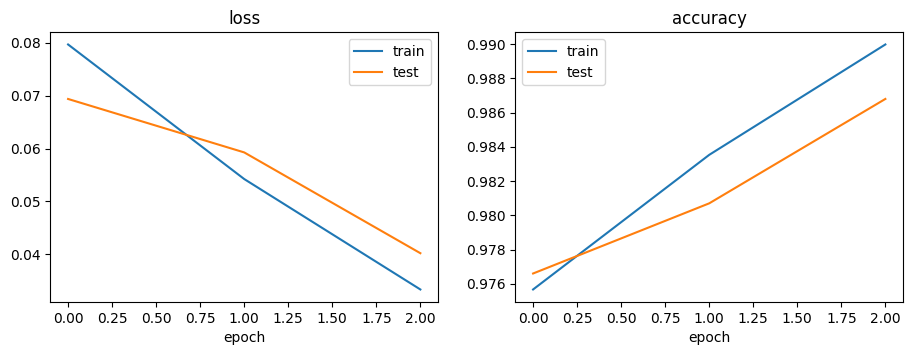

In [24]:
def evaluate(model, loader):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            total_loss += F.cross_entropy(out, yb, reduction="sum").item()
            correct += (out.argmax(1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n

def train_model(model, train_loader, test_loader, epochs=3, lr=1e-3):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}
    for ep in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()                       # clear old gradients
            loss = F.cross_entropy(model(xb), yb) # how wrong are we
            loss.backward()                       # backpropagation
            opt.step()                            # update weights
        tr_l, tr_a = evaluate(model, train_loader)
        te_l, te_a = evaluate(model, test_loader)
        for k, v in zip(hist, [tr_l, te_l, tr_a, te_a]):
            hist[k].append(v)
        print(f"epoch {ep+1}/{epochs} | train loss {tr_l:.4f} acc {tr_a:.4f} | test loss {te_l:.4f} acc {te_a:.4f}")
    return hist

def plot_history(h):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(h["train_loss"], label="train"); ax[0].plot(h["test_loss"], label="test")
    ax[0].set_title("loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(h["train_acc"], label="train"); ax[1].plot(h["test_acc"], label="test")
    ax[1].set_title("accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.show()

history = train_model(model, train_loader, test_loader, epochs=3)
plot_history(history)

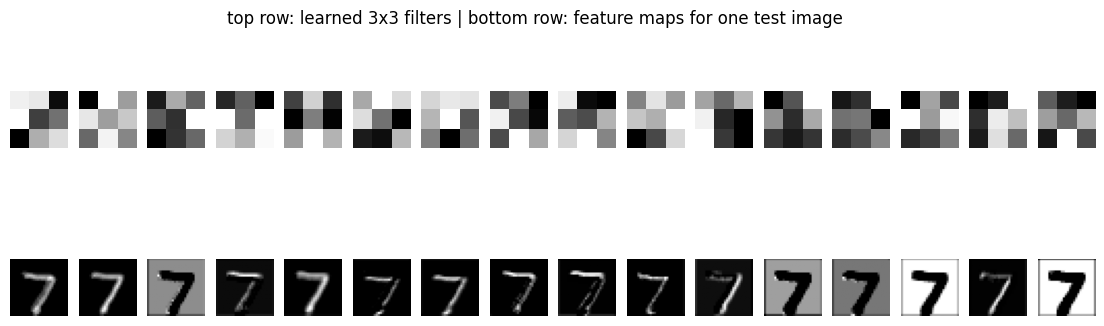

In [25]:
# what did the CNN learn? look at the 16 filters of the first layer and the feature maps they produce
filters = model.conv1.weight.detach().cpu()          # (16, 1, 3, 3)
sample = prep(X_te_raw[:1]).to(device)
with torch.no_grad():
    fmaps = F.relu(model.conv1(sample))[0].cpu()     # (16, 28, 28)

plt.figure(figsize=(14, 4))
for i in range(16):
    plt.subplot(2, 16, i + 1);  plt.imshow(filters[i, 0], cmap="gray"); plt.axis("off")
    plt.subplot(2, 16, 17 + i); plt.imshow(fmaps[i], cmap="gray");      plt.axis("off")
plt.suptitle("top row: learned 3x3 filters | bottom row: feature maps for one test image")
plt.show()

showing 6 mistakes


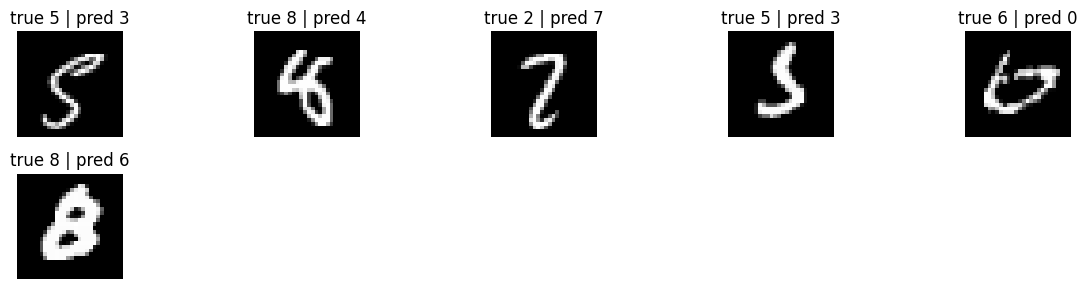

In [26]:
# where does the model make mistakes?
model.eval()
xb, yb = next(iter(test_loader))
with torch.no_grad():
    preds = model(xb.to(device)).argmax(1).cpu()
wrong = (preds != yb).nonzero().flatten()[:10]
print("showing", len(wrong), "mistakes")
plt.figure(figsize=(12, 3))
for k, i in enumerate(wrong):
    plt.subplot(2, 5, k + 1)
    plt.imshow(xb[i, 0], cmap="gray")
    plt.title(f"true {yb[i].item()} | pred {preds[i].item()}")
    plt.axis("off")
plt.tight_layout(); plt.show()

## part 5: handwritten letters (dataset 3: EMNIST letters)

this is the closest to our project. EMNIST letters = handwritten a to z.

**kaggle:** Add Input -> search `emnist` -> pick the one by `crawford` ("EMNIST") -> Add.
**laptop:** download from kaggle, keep `emnist-letters-train.csv` next to this notebook.

each row = 1 label (1 to 26) + 784 pixels. quirk: the images are stored rotated, so we transpose them.
if the file is not found the cell just tells you what to do and the notebook still works.

In [27]:
path = find_file("emnist-letters-train")
print("found:", path)

if path is None:
    print("emnist not found. add the dataset on kaggle (Add Input) or place the csv next to this notebook, then re-run this cell.")
else:
    df_e = pd.read_csv(path, header=None, nrows=40000)   # only 40k rows so it runs fast
    labels = df_e[0].values - 1                          # 1..26 -> 0..25
    imgs = df_e.iloc[:, 1:].values.reshape(-1, 28, 28)
    imgs = np.transpose(imgs, (0, 2, 1))                 # fix the rotation
    print(imgs.shape, labels.shape)

    plt.figure(figsize=(12, 3))
    for i in range(10):
        plt.subplot(2, 5, i + 1)
        plt.imshow(imgs[i], cmap="gray")
        plt.title(chr(ord("a") + labels[i]))
        plt.axis("off")
    plt.tight_layout(); plt.show()

found: None
emnist not found. add the dataset on kaggle (Add Input) or place the csv next to this notebook, then re-run this cell.


### Project: Smart Irrigation Predictor

This project uses a synthetic dataset containing agricultural factors to predict whether a plant or crop field needs watering.

**Dataset Features:**
- **`Soil_moisture`**: The ratio of water content in the soil (scaled between 0 and 1).
- **`temperature_c`**: The ambient temperature in degrees Celsius.
- **`sunlight_hours`**: The daily duration of direct sunlight exposed to the crop.
- **`needs_watering`**: The target binary label (`1` if watering is required, `0` otherwise) which we want to predict.

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

In [ ]:
df=pd.DataFrame({
    "Soil_moisture":[0.14,0.56,0.145,0.25,0.212,0.445,0.25,0.252,0.85,0.76],
    "temperature_c": [25,26,45,32,30,42,36,28,29,42],
    "sunlight_hours":[9,5,8,7,5,10,6,9,8,5],
    "needs_watering":[0,1,1,0,1,0,1,0,1,0]
})

In [ ]:
df


,Soil_moisture,temperature_c,sunlight_hours,needs_watering
0,0.140,25,9,0
1,0.560,26,5,1
2,0.145,45,8,1
3,0.250,32,7,0
4,0.212,30,5,1
5,0.445,42,10,0
6,0.250,36,6,1
7,0.252,28,9,0
8,0.850,29,8,1
9,0.760,42,5,0


In [ ]:
df.columns


Index(['Soil_moisture', 'temperature_c', 'sunlight_hours', 'needs_watering'], dtype='object')

In [ ]:
X=df[["Soil_moisture","temperature_c","sunlight_hours"]]
y=df["needs_watering"]

In [ ]:
X_Min=X.min()
X_Max=X.max()
X_scaled=(X-X_Min)/(X_Max-X_Min +1e-8)

In [ ]:
X_scaled

,Soil_moisture,temperature_c,sunlight_hours
0,0.000000,0.00,0.8
1,0.591549,0.05,0.0
2,0.007042,1.00,0.6
3,0.154930,0.35,0.4
4,0.101408,0.25,0.0
5,0.429577,0.85,1.0
6,0.154930,0.55,0.2
7,0.157746,0.15,0.8
8,1.000000,0.20,0.6
9,0.873239,0.85,0.0


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
X_scaled, y, test_size=0.25, random_state=42,stratify=y)

In [ ]:
model=keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
     layers.Dense(16,activation="relu"),
     layers.Dense(1,activation="sigmoid")
])

In [ ]:
model.compile(optimizer="sgd", loss="binary_crossentropy", metrics=["accuracy"])

In [ ]:
##Batch Gradient Descent
history_full=model.fit(X_train.values,y_train.values,
                  epochs=100,batch_size=X_train.shape[0], verbose=1 )
##Stochastic Gradient Descent
history=model.fit(X_train.values,y_train.values,validation_data=(X_test.values,y_test.values),
                  epochs=100,batch_size=1, verbose=1 )
##Mini Batch Gradient Descent
history_minibatches=model.fit(X_train.values,y_train.values,
                 epochs=100,batch_size=3, verbose=1 )

Epoch 1/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - accuracy: 0.5714 - loss: 0.6394 - val_accuracy: 1.0000 - val_loss: 0.6074
Epoch 2/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.5714 - loss: 0.6397 - val_accuracy: 1.0000 - val_loss: 0.6078
Epoch 3/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.5714 - loss: 0.6385 - val_accuracy: 1.0000 - val_loss: 0.6081
Epoch 4/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.5714 - loss: 0.6382 - val_accuracy: 1.0000 - val_loss: 0.6083
Epoch 5/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.5714 - loss: 0.6380 - val_accuracy: 1.0000 - val_loss: 0.6085
Epoch 6/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.5714 - loss: 0.6384 - val_accuracy: 1.0000 - val_loss: 0.6085
Epoch 7/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.5714 - loss: 0.6378 - val_accuracy: 1.0000 - val_loss: 0.6086
Epoch 8/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.5714 - loss: 0.6386 - val_accuracy: 1.0000 - val_loss

In [ ]:
from tensorflow.keras import optimizers

In [ ]:
opt=optimizers.SGD(learning_rate=0.01, momentum=0.9)
model.compile(optimizer=opt, loss="binary_crossentropy", metrics=["accuracy"])